In [64]:
import numpy as np
import matplotlib.pyplot as plt


In [65]:
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    "text.latex.preamble": r"\usepackage{amsmath} \usepackage{amssymb}"
})

In [66]:
def normalize_posterior(posterior, M_values):
    return posterior / np.trapz(posterior, M_values)

def likelyhood_no_noise(M_values, observations):
    return 1 / M_values**len(observations) * (M_values >= max(observations))

In [67]:
observations = np.array([3.4, 10.2, 2.5])
M_values = np.linspace(0.1, 30, 1000)

posterior = likelyhood_no_noise(M_values, observations)

posterior = normalize_posterior(posterior, M_values)

/var/folders/6k/xt_kj55n7ds1y0cck0fxs9zh0000gp/T/ipykernel_78515/4216355252.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return posterior / np.trapz(posterior, M_values)


Text(0, 0.5, 'Posterior')

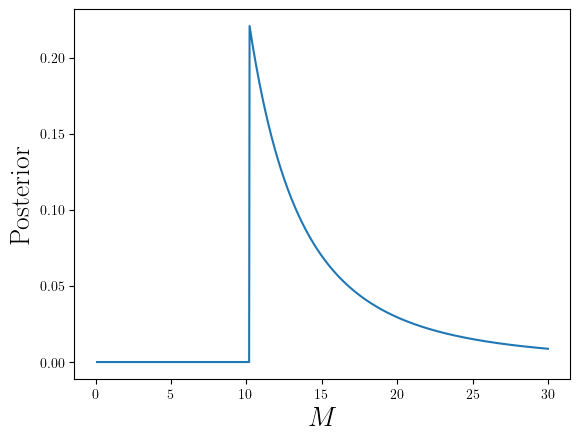

In [68]:
plt.plot(M_values, posterior)
plt.xlabel(r'$M$', fontsize=20)
plt.ylabel('Posterior', fontsize=20)

/var/folders/6k/xt_kj55n7ds1y0cck0fxs9zh0000gp/T/ipykernel_78515/4216355252.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return posterior / np.trapz(posterior, M_values)


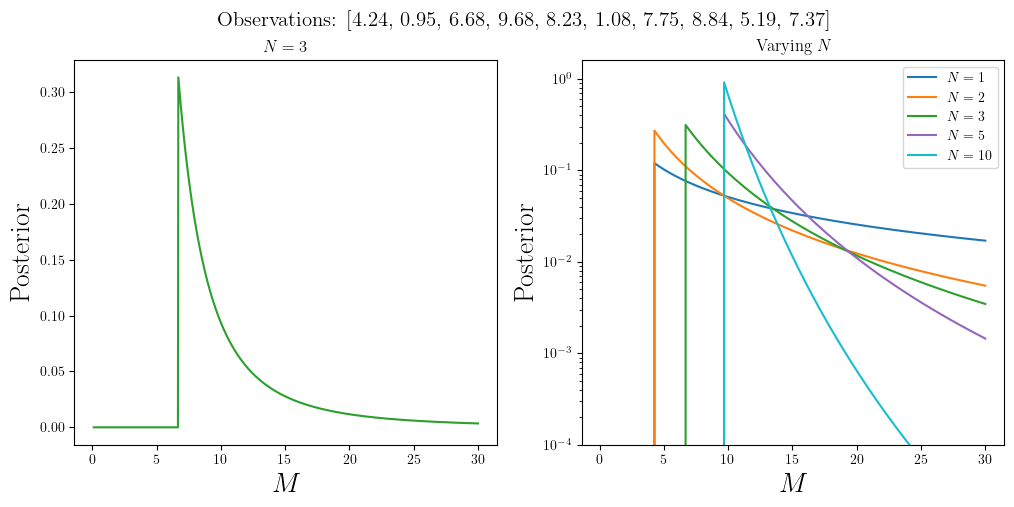

In [69]:
# compute posterior

N_values = [1, 2, 3, 5, 10]

np.random.seed(76450)
observations = np.random.uniform(0, 10, size=max(N_values))

posteriors = {}
for N in N_values:
    observations_N = observations[:N]
    posterior = likelyhood_no_noise(M_values, observations_N)
    posteriors[N] = normalize_posterior(posterior, M_values)

# make sure colors are the same for all N
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(M_values, posteriors[3], color='C2')
axs[0].set_xlabel(r'$M$', fontsize=20)
axs[0].set_ylabel('Posterior', fontsize=20)
axs[0].set_title('$N=3$')

for N, posterior in posteriors.items():
    axs[1].plot(M_values, posterior, label=f'$N={N}$', color=f'C{N-1}')
    axs[1].set_yscale('log')
axs[1].set_xlabel(r'$M$', fontsize=20)
axs[1].set_ylabel('Posterior', fontsize=20)
axs[1].set_title('Varying $N$')
axs[1].set_ylim(1e-4,None)
axs[1].legend()
fig.suptitle(
    f"Observations: [{', '.join(f'{x:.2f}' for x in observations[:max(N_values)])}]",
    fontsize=15
)

plt.savefig('plots/example_uniform_distribution_varying_N.pdf', bbox_inches='tight')

In [76]:
# get observation printed so I can collate with :.2f
print(', '.join(f"{x:.2f}" for x in observations[:max(N_values)]))

4.24, 0.95, 6.68, 9.68, 8.23, 1.08, 7.75, 8.84, 5.19, 7.37


In [70]:
# with measurement uncertainties

# import erf
from scipy.special import erf

def likelihood(M, obs):
    return 1 / M * (erf((M - obs) / np.sqrt(2)) + erf(obs / np.sqrt(2)))

def approximate_likelihood(M, obs):
    return 1 / M * (erf((M - obs) / np.sqrt(2)) + 1)

posterior_noisy = np.prod(likelihood(M_values[:, None], observations[None, :]), axis=1)
posterior_noisy_approx = np.prod(approximate_likelihood(M_values[:, None], observations[None, :]), axis=1)

posterior_noisy = normalize_posterior(posterior_noisy, M_values)
posterior_noisy_approx = normalize_posterior(posterior_noisy_approx, M_values)

/var/folders/6k/xt_kj55n7ds1y0cck0fxs9zh0000gp/T/ipykernel_78515/4216355252.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return posterior / np.trapz(posterior, M_values)


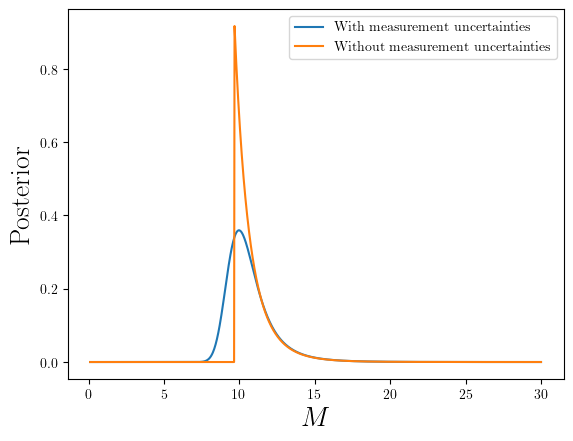

In [71]:
plt.plot(M_values, posterior_noisy, label='With measurement uncertainties')
# plt.plot(M_values, posterior_noisy_approx, label='With measurement uncertainties (approx.)', linestyle='dashed')
plt.plot(M_values, posterior, label='Without measurement uncertainties')
plt.xlabel(r'$M$', fontsize=20)
plt.ylabel('Posterior', fontsize=20)
plt.legend()
plt.savefig('plots/example_uniform_distribution_noisy.pdf', bbox_inches='tight')